# Exploratory analysis of food delivery times

This notebook uses only the training orders from `scripts/split_data.py`. Delivery time is measured in minutes.

In [1]:
from pathlib import Path
import sys

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import display
from matplotlib.patches import Patch

scripts_dir = Path('scripts') if Path('scripts').is_dir() else Path('../scripts')
sys.path.insert(0, str(scripts_dir.resolve()))

from food_delivery_utils import TEST_START, TRAIN_PATH, load_processed

sns.set_theme(style='whitegrid', context='talk', font_scale=0.85)

df = load_processed(TRAIN_PATH)
if df.empty or df['date'].isna().any() or df['date'].ge(TEST_START).any():
    raise ValueError('EDA requires a nonempty dataset with valid dates before the test cutoff.')

print(f"{len(df):,} training orders, {df['date'].min().date()} to {df['date'].max().date()}")
display(df[['target', 'dist_km']].describe().loc[['count', 'mean', '50%', 'min', 'max']].round(2)
        .rename(columns={'target': 'Delivery time (min)', 'dist_km': 'Straight-line distance (km)'}))

34,042 training orders, 2022-02-11 to 2022-03-26


,Delivery time (min),Straight-line distance (km)
count,34042.00,31136.00
mean,26.24,9.59
50%,26.00,9.12
min,10.00,1.47
max,54.00,20.97


## Delivery time and distance

The training orders took 10 to 54 minutes. Longer distances tended to take more time, although orders at similar distances had a wide range of delivery times.

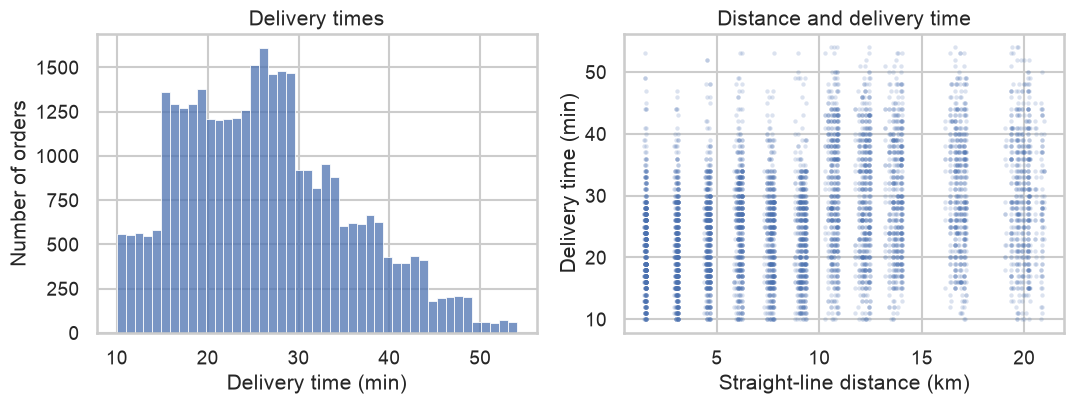

Pearson correlation between distance and time: 0.32


In [2]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
sns.histplot(df['target'], bins=45, ax=axes[0])
axes[0].set(title='Delivery times', xlabel='Delivery time (min)', ylabel='Number of orders')

sample = df.dropna(subset=['dist_km'])
sns.scatterplot(data=sample.sample(min(6000, len(sample)), random_state=0),
                x='dist_km', y='target', s=10, alpha=0.20, linewidth=0, ax=axes[1])
axes[1].set(title='Distance and delivery time', xlabel='Straight-line distance (km)',
            ylabel='Delivery time (min)')
fig.tight_layout()
plt.show()

print(f"Pearson correlation between distance and time: {df['dist_km'].corr(df['target']):.2f}")

## Traffic and weather

Delivery times tended to be longer in heavy traffic and shorter in sunny weather. Orders with missing traffic or weather readings are shown as separate groups.

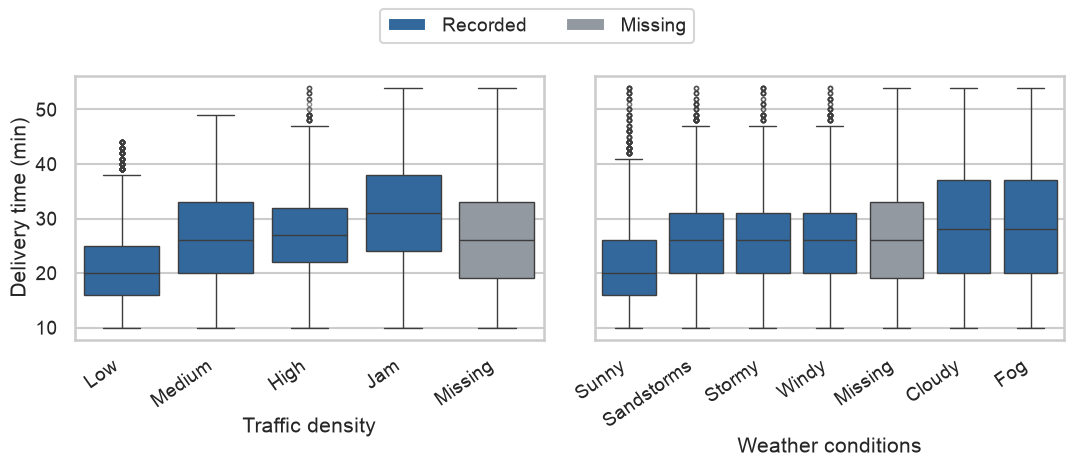

In [3]:
labels = {'Road_traffic_density': 'Traffic density', 'Weatherconditions': 'Weather conditions'}
traffic_order = pd.Index(['Low', 'Medium', 'High', 'Jam', 'Missing'])
colors = {'Recorded': '#32689b', 'Missing': '#9299a1'}

fig, axes = plt.subplots(1, 2, figsize=(11, 4.8), sharey=True)
for ax, (column, label) in zip(axes, labels.items()):
    plot_data = df.assign(value=df[column].fillna('Missing'),
                          status=df[column].isna().map({False: 'Recorded', True: 'Missing'}))
    groups = plot_data.groupby('value')['target'].mean().sort_values().index
    if column == 'Road_traffic_density':
        groups = traffic_order.intersection(groups).append(groups.difference(traffic_order, sort=False))
    sns.boxplot(data=plot_data, x='value', y='target', hue='status', palette=colors,
                order=groups, dodge=False, legend=False, saturation=1,
                flierprops={'markersize': 3, 'alpha': 0.35}, ax=ax)
    ax.set(xlabel=label, ylabel='')
    plt.setp(ax.get_xticklabels(), rotation=35, ha='right')
axes[0].set_ylabel('Delivery time (min)')
fig.legend(handles=[Patch(facecolor=color, label=status) for status, color in colors.items()],
           loc='upper center', ncols=2)
fig.tight_layout(rect=(0, 0, 1, 0.89))
plt.show()

## Daily pattern

Across individual orders, mean delivery time was 28.9 minutes on even-numbered dates and 24.0 minutes on odd-numbered dates. This pattern may reflect how the dataset was generated. Dates without orders appear as gaps.

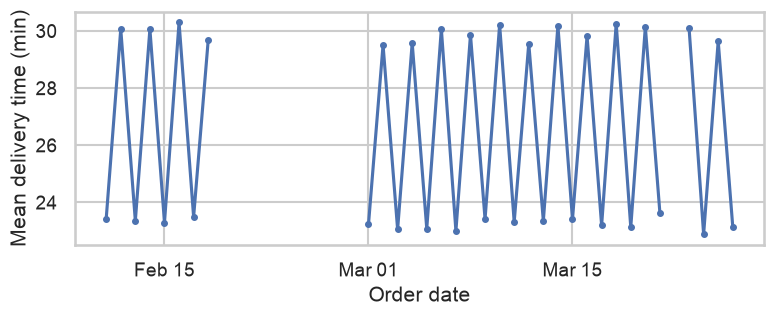

In [4]:
daily_mean = df.groupby('date')['target'].mean().asfreq('D')
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(daily_mean.index, daily_mean, marker='o', markersize=4)
ax.xaxis.set_major_locator(mdates.AutoDateLocator(minticks=3, maxticks=6))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
ax.set(xlabel='Order date', ylabel='Mean delivery time (min)')
fig.tight_layout()
plt.show()